In [123]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


path = "D:\\ML\\ml assignments\\202618001_kaushal_DS605\\202618001_Lab_08\\banknote_authentication.txt"

columns = ["variance", "skewness", "curtosis", "entropy", "class"]

df = pd.read_csv(path, header=None, names=columns)

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


In [124]:

# Dataset information
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Class distribution
print("\nClass distribution:")
print(df["class"].value_counts())

# Statistical summary
display(df.describe())


<class 'pandas.DataFrame'>
RangeIndex: 1372 entries, 0 to 1371
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   variance  1372 non-null   float64
 1   skewness  1372 non-null   float64
 2   curtosis  1372 non-null   float64
 3   entropy   1372 non-null   float64
 4   class     1372 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 53.7 KB

Missing values:
variance    0
skewness    0
curtosis    0
entropy     0
class       0
dtype: int64

Duplicate rows: 24

Class distribution:
class
0    762
1    610
Name: count, dtype: int64


,variance,skewness,curtosis,entropy,class
count,1372.000000,1372.000000,1372.000000,1372.000000,1372.000000
mean,0.433735,1.922353,1.397627,-1.191657,0.444606
std,2.842763,5.869047,4.310030,2.101013,0.497103
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.773000,-1.708200,-1.574975,-2.413450,0.000000
50%,0.496180,2.319650,0.616630,-0.586650,0.000000
75%,2.821475,6.814625,3.179250,0.394810,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


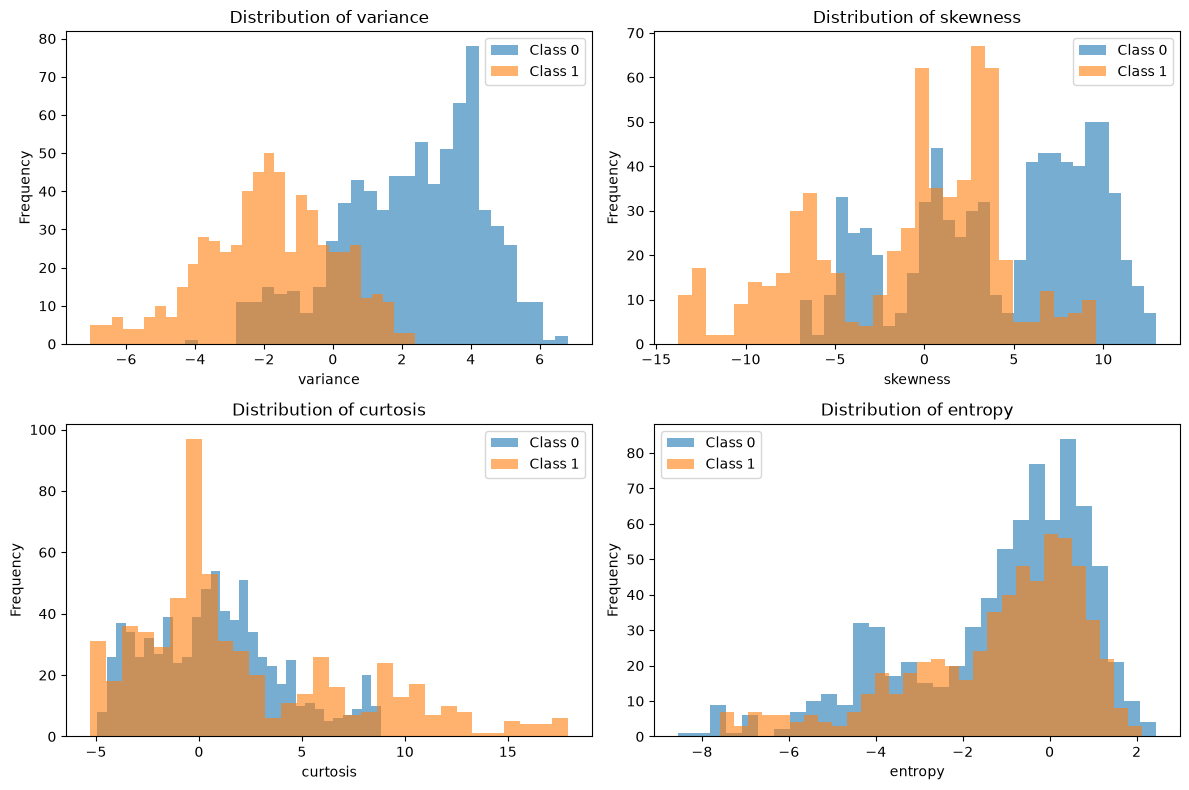

In [125]:

features = ["variance", "skewness", "curtosis", "entropy"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.ravel(), features):
    for label in sorted(df["class"].unique()):
        values = df.loc[df["class"] == label, feature]

        ax.hist(
            values,
            bins=30,
            alpha=0.6,
            label=f"Class {label}"
        )

    ax.set_title(f"Distribution of {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Frequency")
    ax.legend()

plt.tight_layout()
plt.show()


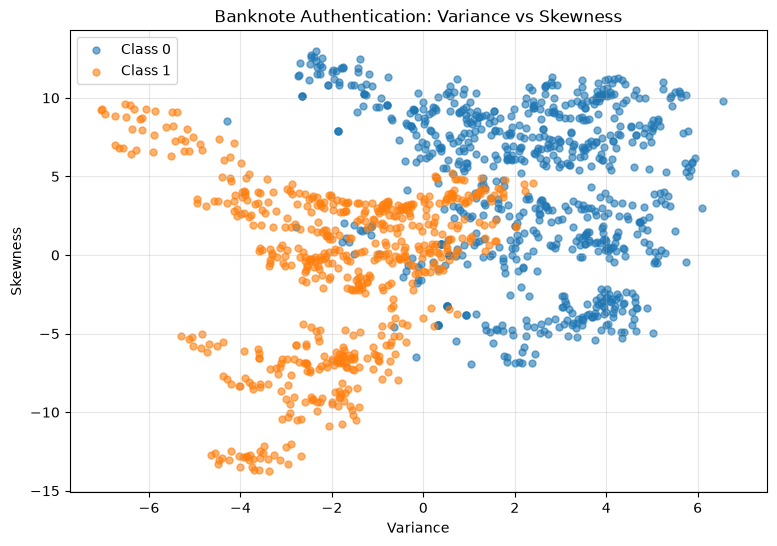

In [126]:

plt.figure(figsize=(9, 6))

for label in sorted(df["class"].unique()):
    subset = df[df["class"] == label]

    plt.scatter(
        subset["variance"],
        subset["skewness"],
        label=f"Class {label}",
        alpha=0.6,
        s=25
    )

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Banknote Authentication: Variance vs Skewness")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


#### Train_test Split


In [127]:

from sklearn.model_selection import train_test_split

# Feature matrices
X_2d = df[["variance", "skewness"]].to_numpy()
X_full = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy()

# Target labels
y = df["class"].to_numpy()

# Split both feature sets using the same rows
X2_train, X2_test, X4_train, X4_test, y_train, y_test = train_test_split(
    X_2d,
    X_full,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("2D Training:", X2_train.shape)
print("2D Testing:", X2_test.shape)

print("4D Training:", X4_train.shape)
print("4D Testing:", X4_test.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)



2D Training: (1097, 2)
2D Testing: (275, 2)
4D Training: (1097, 4)
4D Testing: (275, 4)
Training labels: (1097,)
Testing labels: (275,)


## PART - A


### Decision tree from scratch 

#### Gini and Entropy from scratch

In [128]:

def gini(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1 - np.sum(probabilities ** 2)


def entropy(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(probabilities * np.log2(probabilities))


# Verify using a balanced and a pure node
balanced = np.array([0, 0, 1, 1])
pure = np.array([1, 1, 1, 1])

print("Balanced node:")
print("Gini:", gini(balanced))
print("Entropy:", entropy(balanced))

print("\nPure node:")
print("Gini:", gini(pure))
print("Entropy:", entropy(pure))


Balanced node:
Gini: 0.5
Entropy: 1.0

Pure node:
Gini: 0.0
Entropy: -0.0


#### Find best feature split

In [129]:

def best_split(X, y, criterion="gini", min_samples_leaf=1):
    impurity_fn = gini if criterion == "gini" else entropy

    n_samples, n_features = X.shape
    parent_impurity = impurity_fn(y)

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    for feature in range(n_features):
        values = np.unique(X[:, feature])

        # Midpoints between consecutive unique values
        thresholds = (values[:-1] + values[1:]) / 2

        for threshold in thresholds:
            left_mask = X[:, feature] <= threshold
            right_mask = ~left_mask

            n_left = np.sum(left_mask)
            n_right = n_samples - n_left

            if min(n_left, n_right) < min_samples_leaf:
                continue

            weighted_impurity = (
                n_left / n_samples * impurity_fn(y[left_mask])
                + n_right / n_samples * impurity_fn(y[right_mask])
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature
                best_threshold = threshold

    return best_feature, best_threshold, best_gain


# Test the best split on training data
feature, threshold, gain = best_split(X2_train, y_train)

print("Best feature:", ["variance", "skewness"][feature])
print("Best threshold:", round(threshold, 4))
print("Impurity reduction:", round(gain, 4))


Best feature: variance
Best threshold: 0.7651
Impurity reduction: 0.2421


#### Manual decision tree training 

In [130]:

class ManualDecisionTree:
    def __init__(self, criterion="gini", max_depth=4,
                 min_samples_split=2, min_samples_leaf=1):
        if criterion not in ("gini", "entropy"):
            raise ValueError("criterion must be 'gini' or 'entropy'")

        self.criterion = criterion
        self.max_depth = max_depth
        self.min_samples_split = min_samples_split
        self.min_samples_leaf = min_samples_leaf

    def fit(self, X, y):
        self.root = self._build_tree(X, y, depth=0)
        return self

    def _build_tree(self, X, y, depth):
        # Majority class is the default prediction
        classes, counts = np.unique(y, return_counts=True)
        prediction = classes[np.argmax(counts)]

        node = {
            "prediction": prediction,
            "samples": len(y),
            "feature": None,
            "threshold": None,
            "left": None,
            "right": None
        }

        # Stopping conditions
        if (
            len(classes) == 1
            or (self.max_depth is not None and depth >= self.max_depth)
            or len(y) < self.min_samples_split
            or len(y) < 2 * self.min_samples_leaf
        ):
            return node

        feature, threshold, gain = best_split(
            X, y, self.criterion, self.min_samples_leaf
        )

        if feature is None or gain <= 1e-12:
            return node

        left_mask = X[:, feature] <= threshold
        right_mask = ~left_mask

        node["feature"] = feature
        node["threshold"] = threshold

        node["left"] = self._build_tree(
            X[left_mask], y[left_mask], depth + 1
        )
        node["right"] = self._build_tree(
            X[right_mask], y[right_mask], depth + 1
        )

        return node

    def _predict_one(self, x):
        node = self.root

        while node["feature"] is not None:
            if x[node["feature"]] <= node["threshold"]:
                node = node["left"]
            else:
                node = node["right"]

        return node["prediction"]

    def predict(self, X):
        return np.array([self._predict_one(x) for x in X])


# Train manual Decision Tree
manual_tree = ManualDecisionTree(
    criterion="gini",
    max_depth=4,
    min_samples_leaf=3
)

manual_tree.fit(X2_train, y_train)

y_pred_manual = manual_tree.predict(X2_test)

print("First 10 predictions:", y_pred_manual[:10])
print("Actual labels:      ", y_test[:10])


First 10 predictions: [0 1 0 1 1 1 0 0 0 1]
Actual labels:       [0 1 0 1 1 1 0 0 0 1]


#### 2 feature decision tree visualization

In [131]:

feature_names = ["variance", "skewness"]


def print_tree(node, depth=0):
    indent = "    " * depth

    if node["feature"] is None:
        print(
            f"{indent}Predict Class {node['prediction']} "
            f"(samples={node['samples']})"
        )
        return

    feature = feature_names[node["feature"]]
    threshold = node["threshold"]

    print(f"{indent}If {feature} <= {threshold:.3f}:")
    print_tree(node["left"], depth + 1)

    print(f"{indent}Else ({feature} > {threshold:.3f}):")
    print_tree(node["right"], depth + 1)


print_tree(manual_tree.root)


If variance <= 0.765:
    If skewness <= 5.161:
        If variance <= 0.320:
            If variance <= -0.459:
                Predict Class 1 (samples=346)
            Else (variance > -0.459):
                Predict Class 1 (samples=67)
        Else (variance > 0.320):
            If skewness <= 3.220:
                Predict Class 0 (samples=39)
            Else (skewness > 3.220):
                Predict Class 1 (samples=12)
    Else (skewness > 5.161):
        If variance <= -3.431:
            If variance <= -4.382:
                Predict Class 1 (samples=29)
            Else (variance > -4.382):
                Predict Class 1 (samples=3)
        Else (variance > -3.431):
            If skewness <= 5.533:
                Predict Class 0 (samples=3)
            Else (skewness > 5.533):
                Predict Class 0 (samples=94)
Else (variance > 0.765):
    If variance <= 1.791:
        If skewness <= 4.881:
            If skewness <= 0.664:
                Predict Class 0 (

#### Decision tree boundry comparision

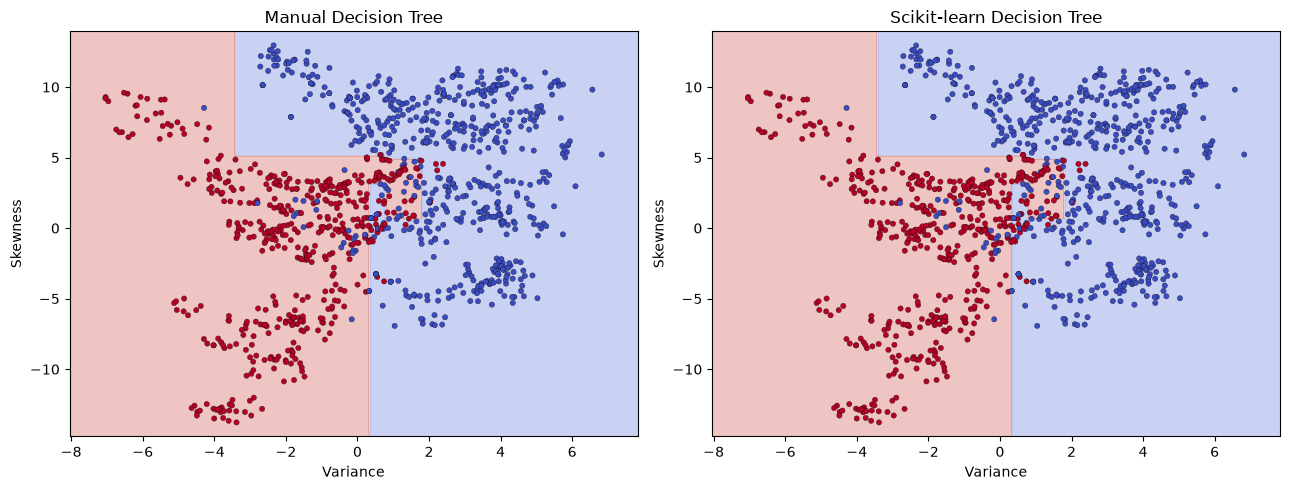

In [132]:

from sklearn.tree import DecisionTreeClassifier

sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    min_samples_leaf=3,
    random_state=42
)

sklearn_tree.fit(X2_train, y_train)

# Create 2D grid for decision-boundary plots
x_min, x_max = X_2d[:, 0].min() - 1, X_2d[:, 0].max() + 1
y_min, y_max = X_2d[:, 1].min() - 1, X_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

models = [
    ("Manual Decision Tree", manual_tree),
    ("Scikit-learn Decision Tree", sklearn_tree)
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (title, model) in zip(axes, models):
    predictions = model.predict(grid_points).reshape(xx.shape)

    ax.contourf(xx, yy, predictions, alpha=0.3, cmap="coolwarm")

    ax.scatter(
        X2_train[:, 0],
        X2_train[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="k",
        linewidths=0.2,
        s=15
    )

    ax.set_title(title)
    ax.set_xlabel("Variance")
    ax.set_ylabel("Skewness")

plt.tight_layout()
plt.show()


#### Hyperpara and parameter comparision 

,criterion,max_depth,manual_train,manual_test,sk_train,sk_test,agreement
0,gini,1,0.8423,0.8291,0.8423,0.8291,1.0000
1,gini,2,0.9015,0.8764,0.9015,0.8764,1.0000
2,gini,3,0.9289,0.9091,0.9289,0.9091,1.0000
3,gini,4,0.9426,0.9345,0.9426,0.9345,1.0000
4,gini,5,0.9462,0.9309,0.9462,0.9309,1.0000
5,gini,6,0.9508,0.9309,0.9508,0.9309,1.0000
6,gini,8,0.9699,0.9309,0.9699,0.9309,1.0000
7,gini,10,0.9736,0.9273,0.9736,0.9273,0.9927
8,entropy,1,0.8423,0.8291,0.8423,0.8291,1.0000
9,entropy,2,0.9015,0.8764,0.9015,0.8764,1.0000


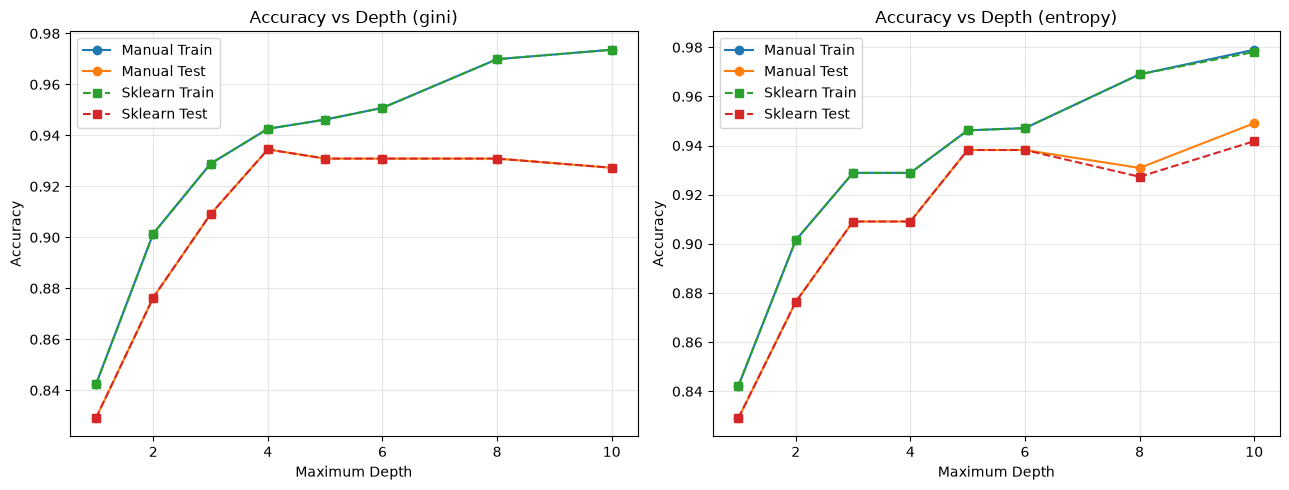

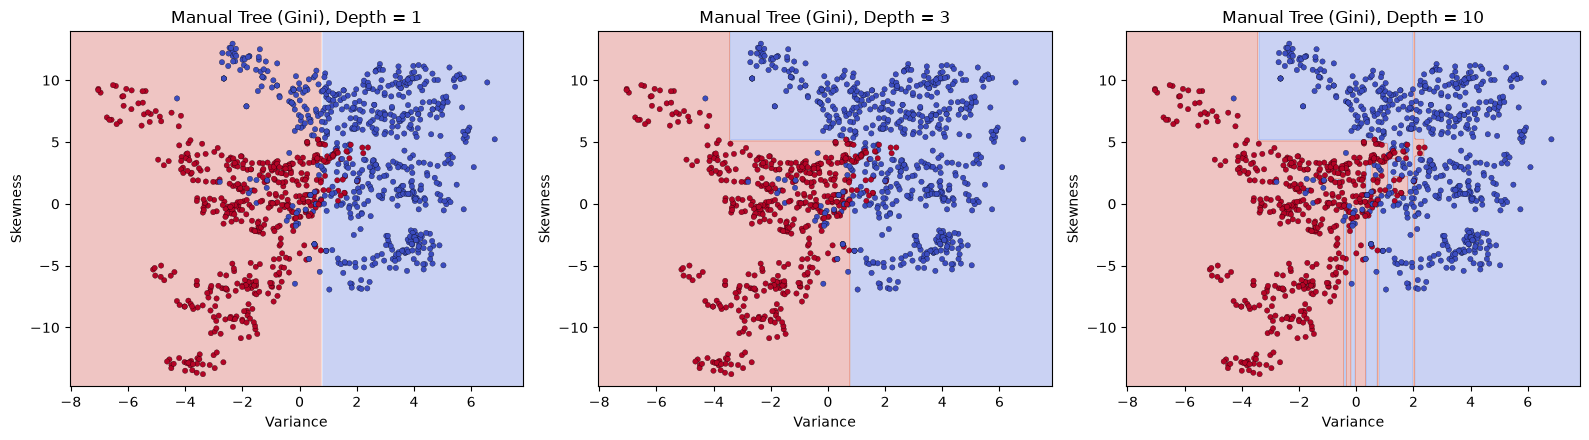

In [133]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

rows = []
trained_trees = {}

# Compare Gini and Entropy for different depths
for crit in ["gini", "entropy"]:
    for d in [1, 2, 3, 4, 5, 6, 8, 10]:

        # Manual Decision Tree
        manual = ManualDecisionTree(
            criterion=crit,
            max_depth=d,
            min_samples_leaf=3
        )
        manual.fit(X2_train, y_train)

        # Scikit-learn Decision Tree
        sk = DecisionTreeClassifier(
            criterion=crit,
            max_depth=d,
            min_samples_leaf=3,
            random_state=42
        )
        sk.fit(X2_train, y_train)

        manual_train_pred = manual.predict(X2_train)
        manual_test_pred = manual.predict(X2_test)
        sk_test_pred = sk.predict(X2_test)

        trained_trees[(crit, d)] = manual

        rows.append({
            "criterion": crit,
            "max_depth": d,
            "manual_train": accuracy_score(y_train, manual_train_pred),
            "manual_test": accuracy_score(y_test, manual_test_pred),
            "sk_train": sk.score(X2_train, y_train),
            "sk_test": sk.score(X2_test, y_test),
            "agreement": np.mean(manual_test_pred == sk_test_pred)
        })

results_tree = pd.DataFrame(rows).round(4)
display(results_tree)


# Plot 1: Accuracy vs Maximum Depth
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for i, crit in enumerate(["gini", "entropy"]):
    r = results_tree[results_tree["criterion"] == crit]

    axes[i].plot(r["max_depth"], r["manual_train"],
                 "o-", label="Manual Train")
    axes[i].plot(r["max_depth"], r["manual_test"],
                 "o-", label="Manual Test")
    axes[i].plot(r["max_depth"], r["sk_train"],
                 "s--", label="Sklearn Train")
    axes[i].plot(r["max_depth"], r["sk_test"],
                 "s--", label="Sklearn Test")

    axes[i].set_title(f"Accuracy vs Depth ({crit})")
    axes[i].set_xlabel("Maximum Depth")
    axes[i].set_ylabel("Accuracy")
    axes[i].legend()
    axes[i].grid(alpha=0.3)

plt.tight_layout()
plt.show()


# Plot 2: Decision Boundaries at Different Depths
x_min, x_max = X2_train[:, 0].min() - 1, X2_train[:, 0].max() + 1
y_min, y_max = X2_train[:, 1].min() - 1, X2_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid_points_tree = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, d in zip(axes, [1, 3, 10]):
    model = trained_trees[("gini", d)]

    Z = model.predict(grid_points_tree).reshape(xx.shape)

    ax.contourf(xx, yy, Z, cmap="coolwarm", alpha=0.3)

    ax.scatter(
        X2_train[:, 0],
        X2_train[:, 1],
        c=y_train,
        cmap="coolwarm",
        edgecolors="k",
        linewidths=0.2,
        s=15
    )

    ax.set_title(f"Manual Tree (Gini), Depth = {d}")
    ax.set_xlabel("Variance")
    ax.set_ylabel("Skewness")

plt.tight_layout()
plt.show()


## PART B


### Linear Svm from scratch 


### Feature Scaling and Label Conversion

In [134]:

# Calculate statistics using training data only
mean = X2_train.mean(axis=0)
std = X2_train.std(axis=0)
std[std == 0] = 1

# Standardize features
X2_train_scaled = (X2_train - mean) / std
X2_test_scaled = (X2_test - mean) / std

# Convert labels: 0 -> -1, 1 -> +1
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("Feature means:", mean)
print("Feature standard deviations:", std)
print("SVM classes:", np.unique(y_train_svm))
print("Scaled training shape:", X2_train_scaled.shape)


Feature means: [0.46348197 1.87278442]
Feature standard deviations: [2.83946429 5.90458812]
SVM classes: [-1  1]
Scaled training shape: (1097, 2)


### Manusal linear SVM

In [135]:

class ManualLinearSVM:
    def __init__(self, C=1.0, learning_rate=0.05, n_iterations=3000):
        self.C = C
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        n_samples, n_features = X.shape

        self.w = np.zeros(n_features)
        self.b = 0.0
        self.loss_history = []

        for iteration in range(self.n_iterations):
            # Signed distance before normalization by ||w||
            scores = X @ self.w + self.b
            margins = y * scores

            # Samples with positive hinge loss
            violations = margins < 1

            # Subgradients of normalized objective
            dw = (
                self.w / n_samples
                - self.C * (X[violations].T @ y[violations]) / n_samples
            )

            db = (
                -self.C * np.sum(y[violations]) / n_samples
            )

            # Gradually decrease learning rate
            lr = self.learning_rate / (1 + 0.001 * iteration)

            self.w -= lr * dw
            self.b -= lr * db

            # Record current loss
            scores = X @ self.w + self.b
            hinge = np.maximum(0, 1 - y * scores)

            loss = (
                0.5 * np.dot(self.w, self.w)
                + self.C * np.sum(hinge)
            ) / n_samples

            self.loss_history.append(loss)

        return self

    def decision_function(self, X):
        return X @ self.w + self.b

    def predict(self, X):
        scores = self.decision_function(X)
        return np.where(scores >= 0, 1, -1)


### Train the svm and plot the loss

Weights: [-1.9483703  -1.21587042]
Bias: -0.24254342959600483
Manual SVM Accuracy: 0.88


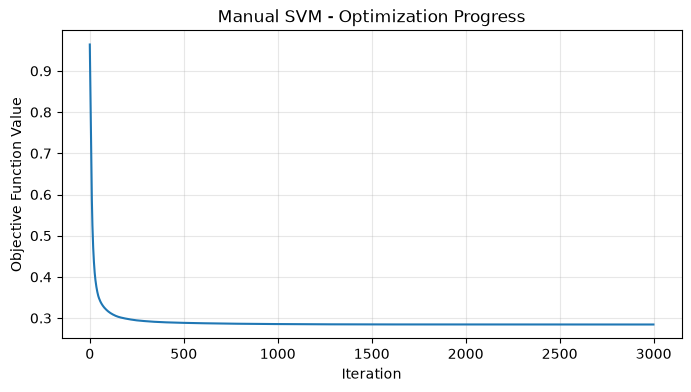

In [136]:

manual_svm = ManualLinearSVM(
    C=1.0,
    learning_rate=0.05,
    n_iterations=3000
)

manual_svm.fit(X2_train_scaled, y_train_svm)

pred_manual_svm = manual_svm.predict(X2_test_scaled)

print("Weights:", manual_svm.w)
print("Bias:", manual_svm.b)

print(
    "Manual SVM Accuracy:",
    accuracy_score(y_test_svm, pred_manual_svm)
)

# Plot optimization progress
plt.figure(figsize=(8, 4))
plt.plot(manual_svm.loss_history)

plt.xlabel("Iteration")
plt.ylabel("Objective Function Value")
plt.title("Manual SVM - Optimization Progress")
plt.grid(alpha=0.3)
plt.show()


### Visualize Boundary, Margins and Violations

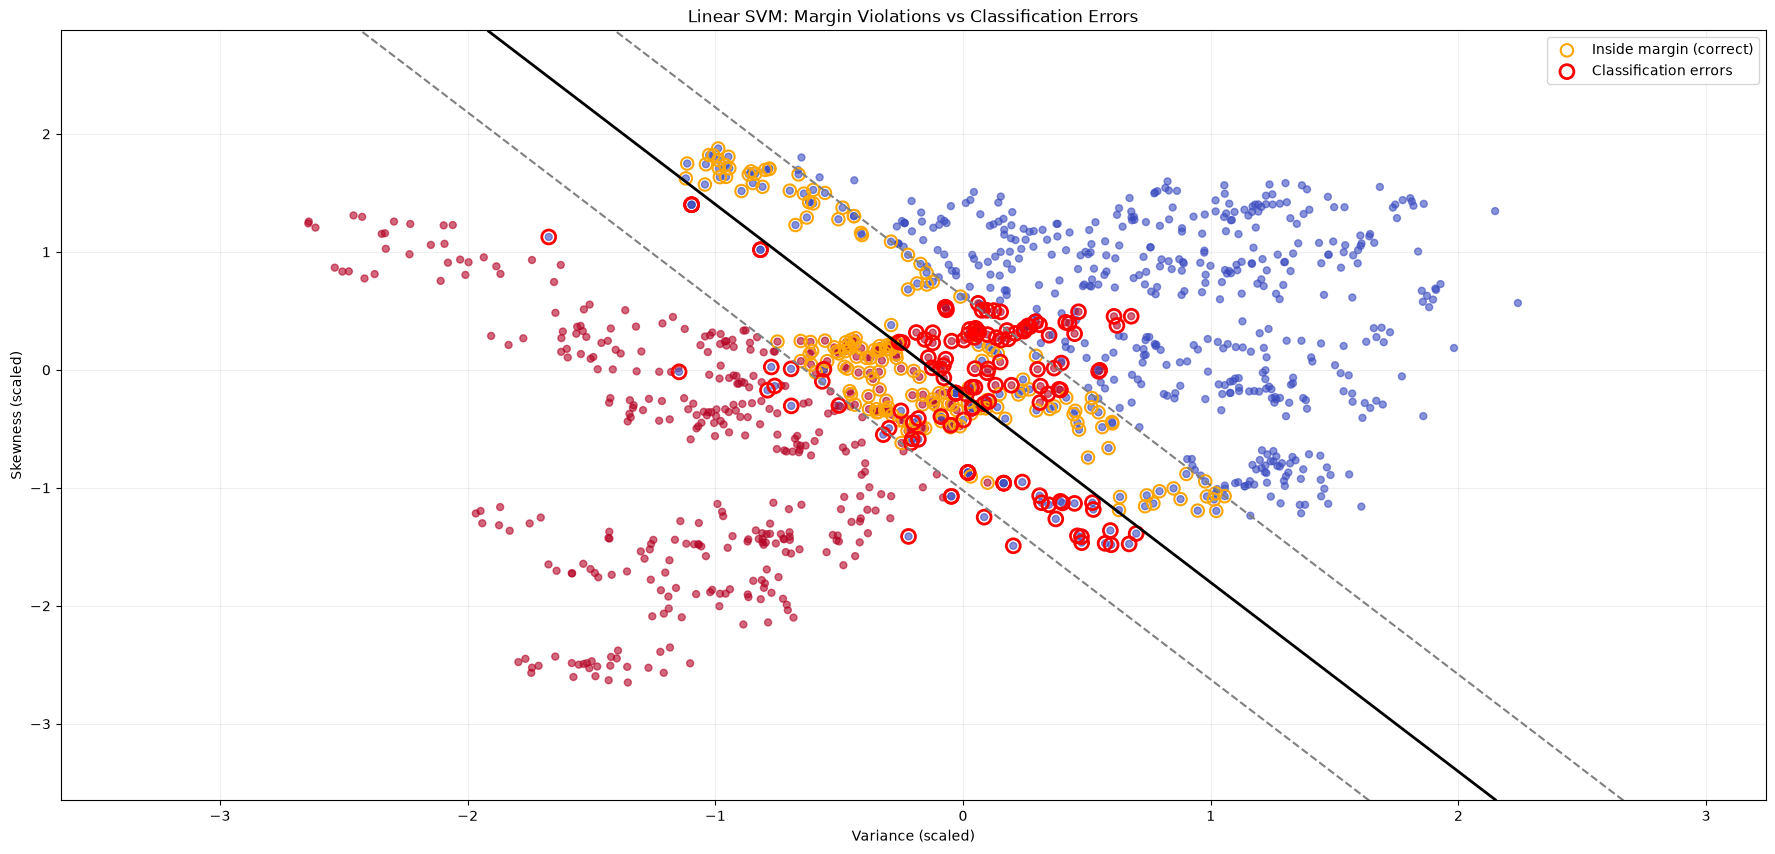

Correct but inside margin: 187
Misclassified points: 133
On decision boundary: 0
Total margin violations: 320


In [137]:

# Calculate signed margins
train_scores = manual_svm.decision_function(X2_train_scaled)
signed_margin = y_train_svm * train_scores

# Separate categories
inside_margin = (signed_margin > 0) & (signed_margin < 1)
misclassified = signed_margin < 0
on_boundary = signed_margin == 0

# Decision function on grid
# Create a grid in scaled feature space
x_min, x_max = X2_train_scaled[:, 0].min() - 1, X2_train_scaled[:, 0].max() + 1
y_min, y_max = X2_train_scaled[:, 1].min() - 1, X2_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.c_[xx.ravel(), yy.ravel()]
scores = manual_svm.decision_function(grid).reshape(xx.shape)

plt.figure(figsize=(22, 10))

# All training samples
plt.scatter(
    X2_train_scaled[:, 0],
    X2_train_scaled[:, 1],
    c=y_train,
    cmap="coolwarm",
    s=25,
    alpha=0.6
)

# Decision boundary and margins
plt.contour(
    xx, yy, scores,
    levels=[-1, 0, 1],
    colors=["gray", "black", "gray"],
    linestyles=["--", "-", "--"],
    linewidths=[1.5, 2, 1.5]
)

# Correctly classified but inside margin
plt.scatter(
    X2_train_scaled[inside_margin, 0],
    X2_train_scaled[inside_margin, 1],
    facecolors="none",
    edgecolors="orange",
    s=80,
    linewidths=1.5,
    label="Inside margin (correct)"
)

# Misclassified points
plt.scatter(
    X2_train_scaled[misclassified, 0],
    X2_train_scaled[misclassified, 1],
    facecolors="none",
    edgecolors="red",
    s=100,
    linewidths=2,
    label="Classification errors"
)

plt.xlabel("Variance (scaled)")
plt.ylabel("Skewness (scaled)")
plt.title("Linear SVM: Margin Violations vs Classification Errors")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Correct but inside margin:", np.sum(inside_margin))
print("Misclassified points:", np.sum(misclassified))
print("On decision boundary:", np.sum(on_boundary))
print("Total margin violations:", np.sum(signed_margin < 1))


### Compare With Scikit-learn Linear SVM

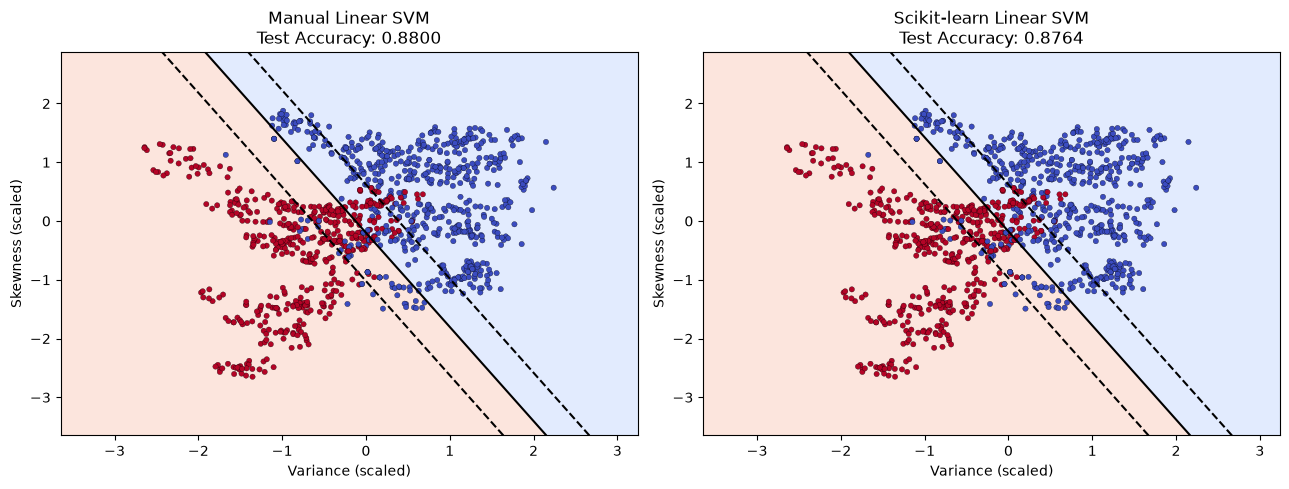

In [138]:

from sklearn.svm import SVC

sklearn_svm = SVC(kernel="linear", C=1.0)
sklearn_svm.fit(X2_train_scaled, y_train_svm)

models = [
    ("Manual Linear SVM", manual_svm),
    ("Scikit-learn Linear SVM", sklearn_svm)
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, models):
    scores = model.decision_function(grid).reshape(xx.shape)

    ax.contourf(
        xx, yy, scores,
        levels=[-1000, 0, 1000],
        cmap="coolwarm",
        alpha=0.25
    )

    ax.contour(
        xx, yy, scores,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"]
    )

    ax.scatter(
        X2_train_scaled[:, 0],
        X2_train_scaled[:, 1],
        c=y_train,
        cmap="coolwarm",
        s=15,
        edgecolors="k",
        linewidths=0.2
    )

    accuracy = accuracy_score(
        y_test_svm, model.predict(X2_test_scaled)
    )

    ax.set_title(f"{name}\nTest Accuracy: {accuracy:.4f}")
    ax.set_xlabel("Variance (scaled)")
    ax.set_ylabel("Skewness (scaled)")

plt.tight_layout()
plt.show()


In [139]:

# Extract learned parameters
manual_w = manual_svm.w
manual_b = manual_svm.b

sklearn_w = sklearn_svm.coef_[0]
sklearn_b = sklearn_svm.intercept_[0]

comparison = pd.DataFrame({
    "Parameter": [
        "Weight (Variance)",
        "Weight (Skewness)",
        "Bias",
        "Weight Norm",
        "Margin Width",
        "Test Accuracy"
    ],
    "Manual SVM": [
        manual_w[0],
        manual_w[1],
        manual_b,
        np.linalg.norm(manual_w),
        2 / np.linalg.norm(manual_w),
        accuracy_score(
            y_test_svm,
            manual_svm.predict(X2_test_scaled)
        )
    ],
    "Scikit-learn SVM": [
        sklearn_w[0],
        sklearn_w[1],
        sklearn_b,
        np.linalg.norm(sklearn_w),
        2 / np.linalg.norm(sklearn_w),
        accuracy_score(
            y_test_svm,
            sklearn_svm.predict(X2_test_scaled)
        )
    ]
})

display(comparison.round(4))

print("Weight difference:",
      np.linalg.norm(manual_w - sklearn_w))

print("Bias difference:",
      abs(manual_b - sklearn_b))


,Parameter,Manual SVM,Scikit-learn SVM
0,Weight (Variance),-1.9484,-2.0093
1,Weight (Skewness),-1.2159,-1.2550
2,Bias,-0.2425,-0.2211
3,Weight Norm,2.2966,2.3690
4,Margin Width,0.8708,0.8442
5,Test Accuracy,0.8800,0.8764


Weight difference: 0.0724212565575601
Bias difference: 0.021446252345512756


### Effect of Regularization Parameter C

,C,Train Accuracy,Margin Violations,Weight Norm,Final Loss
0,0.01,0.883318,986,0.538781,0.005685
1,0.10,0.883318,449,1.480463,0.031522
2,1.00,0.878760,320,2.296625,0.284449
3,10.00,0.880583,310,2.428472,2.820400


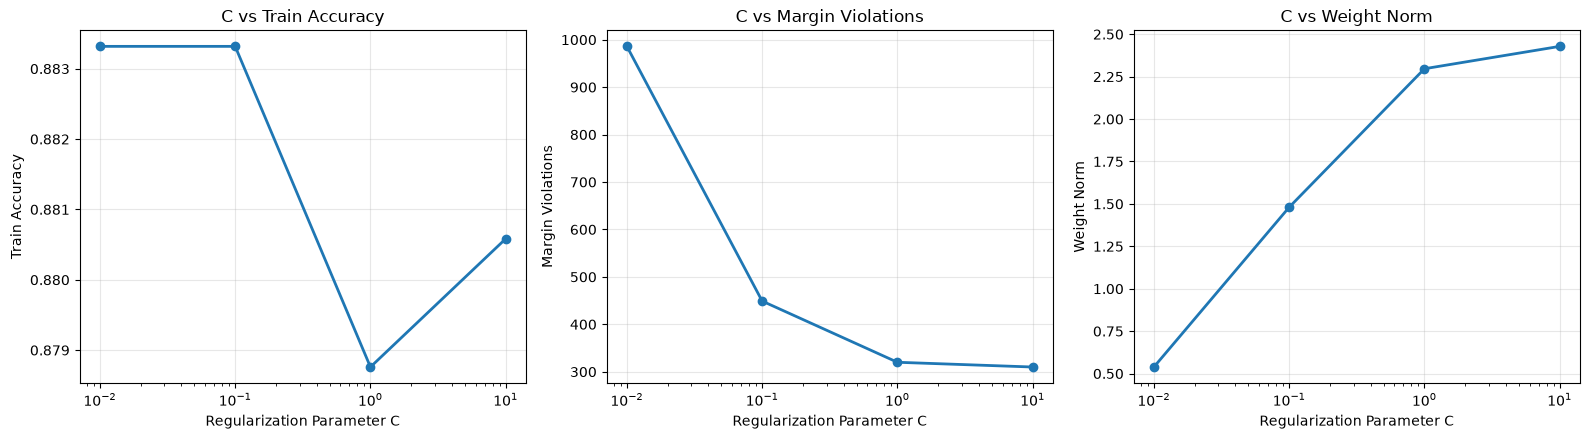

In [140]:

C_values = [0.01, 0.1, 1, 10]
c_results = []

for C in C_values:
    model = ManualLinearSVM(
        C=C,
        learning_rate=0.05,
        n_iterations=3000
    )

    model.fit(X2_train_scaled, y_train_svm)

    train_scores = model.decision_function(X2_train_scaled)

    c_results.append({
        "C": C,
        "Train Accuracy": accuracy_score(
            y_train_svm, model.predict(X2_train_scaled)
        ),
        "Margin Violations": np.sum(y_train_svm * train_scores < 1),
        "Weight Norm": np.linalg.norm(model.w),
        "Final Loss": model.loss_history[-1]
    })

display(pd.DataFrame(c_results))



results_C = pd.DataFrame(c_results)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

metrics = ["Train Accuracy", "Margin Violations", "Weight Norm"]

for ax, metric in zip(axes, metrics):
    ax.plot(
        results_C["C"],
        results_C[metric],
        marker="o",
        linewidth=2
    )

    ax.set_xscale("log")
    ax.set_xlabel("Regularization Parameter C")
    ax.set_ylabel(metric)
    ax.set_title(f"C vs {metric}")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()



### Decision Boundaries for Different C Values

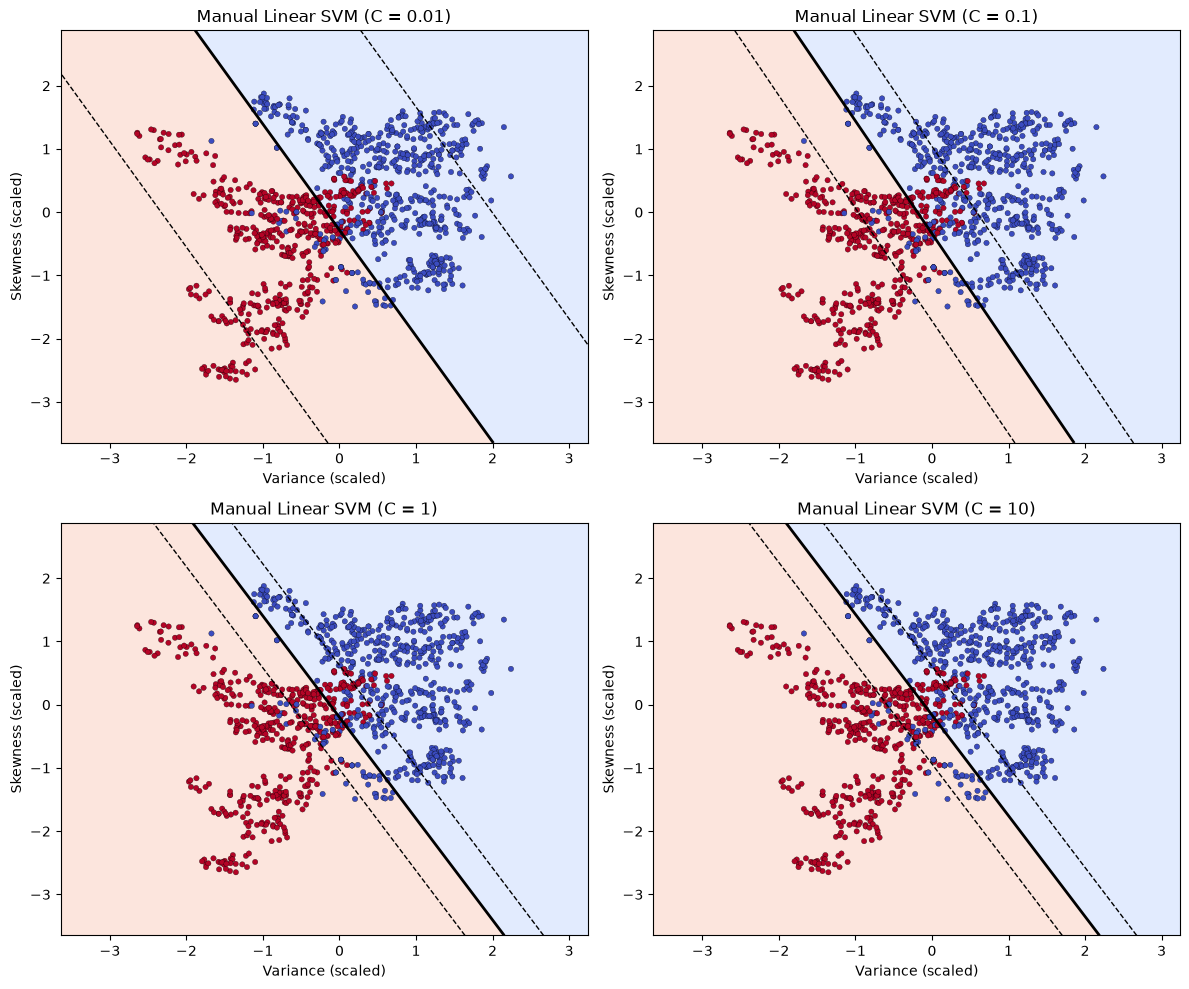

In [141]:

x_min = X2_train_scaled[:, 0].min() - 1
x_max = X2_train_scaled[:, 0].max() + 1
y_min = X2_train_scaled[:, 1].min() - 1
y_max = X2_train_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid_points = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, C in zip(axes.ravel(), C_values):

    model = ManualLinearSVM(
        C=C,
        learning_rate=0.05,
        n_iterations=3000
    )
    model.fit(X2_train_scaled, y_train_svm)

    scores = model.decision_function(grid_points).reshape(xx.shape)

    # Decision regions
    ax.contourf(
        xx, yy, scores,
        levels=[-1000, 0, 1000],
        cmap="coolwarm",
        alpha=0.25
    )

    # Decision boundary and margins
    ax.contour(
        xx, yy, scores,
        levels=[-1, 0, 1],
        colors="black",
        linestyles=["--", "-", "--"],
        linewidths=[1, 2, 1]
    )

    ax.scatter(
        X2_train_scaled[:, 0],
        X2_train_scaled[:, 1],
        c=y_train,
        cmap="coolwarm",
        s=15,
        edgecolors="k",
        linewidths=0.2
    )

    ax.set_title(f"Manual Linear SVM (C = {C})")
    ax.set_xlabel("Variance (scaled)")
    ax.set_ylabel("Skewness (scaled)")

plt.tight_layout()
plt.show()


### Effect of Learning Rate and Iterations

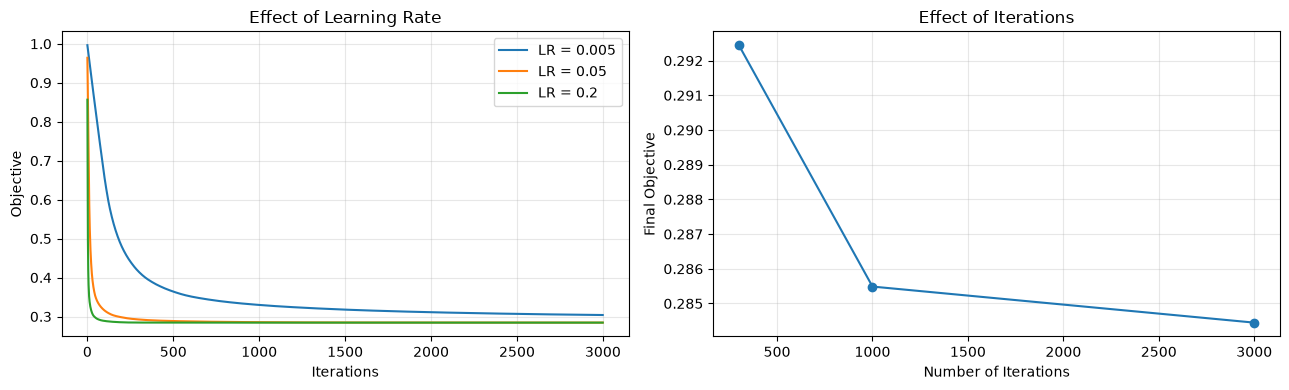

In [142]:

learning_rates = [0.005, 0.05, 0.2]
iteration_values = [300, 1000, 3000]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Effect of learning rate
for lr in learning_rates:
    model = ManualLinearSVM(
        C=1.0,
        learning_rate=lr,
        n_iterations=3000
    )
    model.fit(X2_train_scaled, y_train_svm)

    axes[0].plot(
        model.loss_history,
        label=f"LR = {lr}"
    )

axes[0].set_title("Effect of Learning Rate")
axes[0].set_xlabel("Iterations")
axes[0].set_ylabel("Objective")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Effect of iteration count
iteration_results = []

for n_iter in iteration_values:
    model = ManualLinearSVM(
        C=1.0,
        learning_rate=0.05,
        n_iterations=n_iter
    )
    model.fit(X2_train_scaled, y_train_svm)

    iteration_results.append(model.loss_history[-1])

axes[1].plot(iteration_values, iteration_results, marker="o")
axes[1].set_title("Effect of Iterations")
axes[1].set_xlabel("Number of Iterations")
axes[1].set_ylabel("Final Objective")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## Part C

### Kernel SVM and Nonlinear Decision Boundaries

### Generate a Nonlinear Dataset

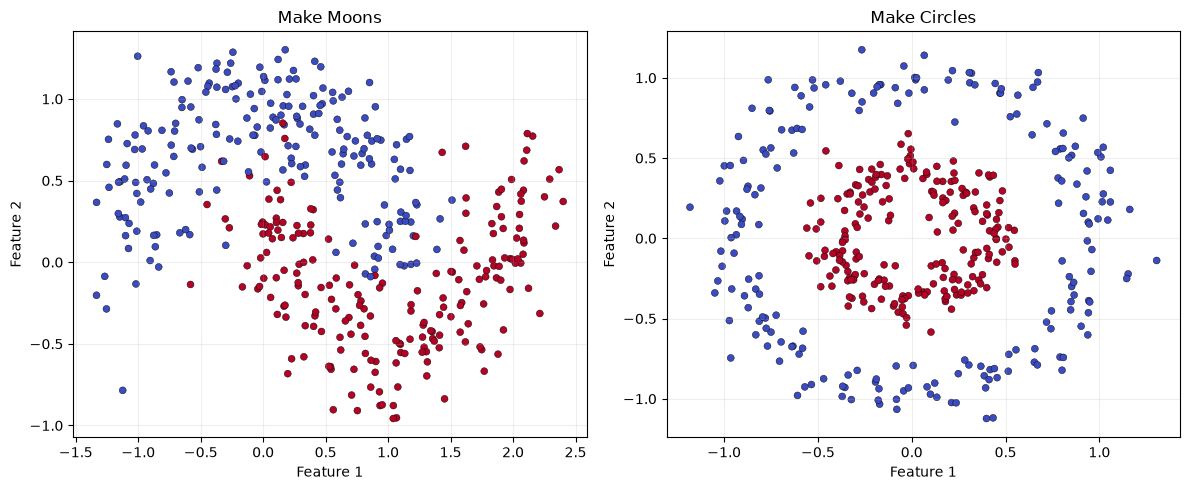

In [143]:

from sklearn.datasets import make_moons, make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Generate both datasets
X_moons, y_moons = make_moons(
    n_samples=400,
    noise=0.22,
    random_state=42
)

X_circles, y_circles = make_circles(
    n_samples=400,
    factor=0.4,
    noise=0.10,
    random_state=42
)

datasets = {
    "Moons": (X_moons, y_moons),
    "Circles": (X_circles, y_circles)
}

# Visualize both datasets
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, (X, y)) in zip(axes, datasets.items()):
    ax.scatter(
        X[:, 0], X[:, 1],
        c=y,
        cmap="coolwarm",
        edgecolors="k",
        linewidths=0.3,
        s=25
    )

    ax.set_title(f"Make {name}")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


### Split and Scale Both Datasets

In [144]:

prepared_data = {}

for name, (X, y) in datasets.items():

    X_train, X_test, y_train_c, y_test_c = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    scaler = StandardScaler()

    X_train = scaler.fit_transform(X_train)
    X_test = scaler.transform(X_test)

    prepared_data[name] = {
        "X_train": X_train,
        "X_test": X_test,
        "y_train": y_train_c,
        "y_test": y_test_c
    }

    print(
        f"{name}: Train = {X_train.shape}, "
        f"Test = {X_test.shape}"
    )


Moons: Train = (320, 2), Test = (80, 2)
Circles: Train = (320, 2), Test = (80, 2)


### Train All Three SVM Kernels(linear,poly,rbf)

In [145]:

kernel_models = {}
kernel_results = []

for name, data in prepared_data.items():

    models = {
        "Linear": SVC(kernel="linear", C=1.0),

        "Polynomial": SVC(
            kernel="poly",
            degree=3,
            C=1.0,
            gamma="scale",
            coef0=1.0
        ),

        "RBF": SVC(
            kernel="rbf",
            C=1.0,
            gamma="scale"
        )
    }

    kernel_models[name] = models

    for kernel, model in models.items():

        model.fit(data["X_train"], data["y_train"])

        train_acc = model.score(
            data["X_train"], data["y_train"]
        )

        test_acc = model.score(
            data["X_test"], data["y_test"]
        )

        kernel_results.append({
            "Dataset": name,
            "Kernel": kernel,
            "Train Accuracy": train_acc,
            "Test Accuracy": test_acc,
            "Gap": train_acc - test_acc,
            "Support Vectors": len(model.support_)
        })

results_kernel = pd.DataFrame(kernel_results)
display(results_kernel.round(4))


,Dataset,Kernel,Train Accuracy,Test Accuracy,Gap,Support Vectors
0,Moons,Linear,0.8188,0.9375,-0.1188,125
1,Moons,Polynomial,0.9531,0.9500,0.0031,74
2,Moons,RBF,0.9594,0.9750,-0.0156,88
3,Circles,Linear,0.5969,0.5500,0.0469,318
4,Circles,Polynomial,0.9969,1.0000,-0.0031,15
5,Circles,RBF,0.9969,1.0000,-0.0031,40


### Visualize All Six Decision Boundaries

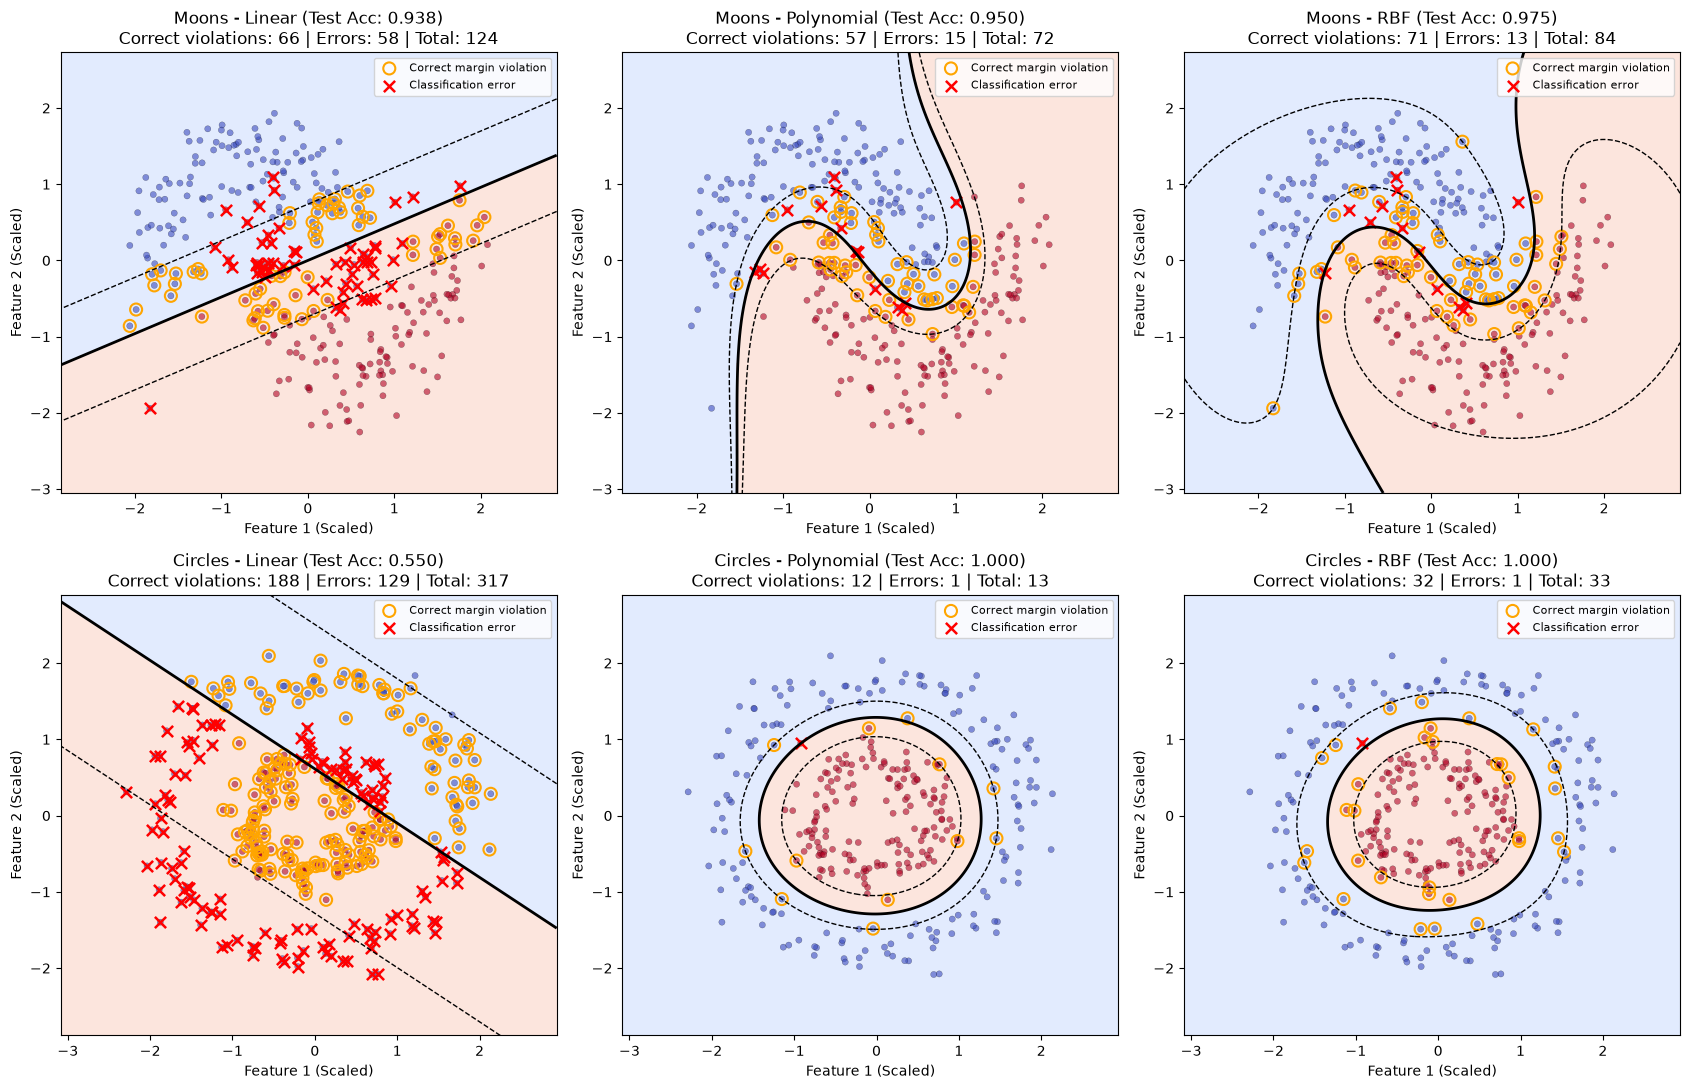

,Dataset,Kernel,Correct Margin Violations,Classification Errors,Total Margin Violations
0,Moons,Linear,66,58,124
1,Moons,Polynomial,57,15,72
2,Moons,RBF,71,13,84
3,Circles,Linear,188,129,317
4,Circles,Polynomial,12,1,13
5,Circles,RBF,32,1,33


In [146]:

fig, axes = plt.subplots(2, 3, figsize=(17, 11))

violation_results = []

for i, (name, data) in enumerate(prepared_data.items()):

    X = data["X_train"]
    y = data["y_train"]

    # Create grid
    xx, yy = np.meshgrid(
        np.linspace(X[:, 0].min() - 0.8,
                    X[:, 0].max() + 0.8, 250),
        np.linspace(X[:, 1].min() - 0.8,
                    X[:, 1].max() + 0.8, 250)
    )

    grid_points = np.c_[xx.ravel(), yy.ravel()]

    for j, (kernel, model) in enumerate(kernel_models[name].items()):

        ax = axes[i, j]

        # Decision function on grid
        scores = model.decision_function(grid_points).reshape(xx.shape)
        predictions = model.predict(grid_points).reshape(xx.shape)

        # Decision function on training samples
        train_scores = model.decision_function(X)
        train_predictions = model.predict(X)

        # Convert labels to -1 and +1
        y_signed = np.where(y == model.classes_[1], 1, -1)

        signed_margin = y_signed * train_scores

        # Classification categories
        errors = train_predictions != y

        correct_inside = (
            (signed_margin < 1) & (~errors)
        )

        margin_violations = signed_margin < 1

        # Counts
        n_correct_inside = np.sum(correct_inside)
        n_errors = np.sum(errors)
        n_violations = np.sum(margin_violations)

        violation_results.append({
            "Dataset": name,
            "Kernel": kernel,
            "Correct Margin Violations": n_correct_inside,
            "Classification Errors": n_errors,
            "Total Margin Violations": n_violations
        })

        # Decision regions
        ax.contourf(
            xx, yy, predictions,
            levels=[-0.5, 0.5, 1.5],
            cmap="coolwarm",
            alpha=0.25
        )

        # Boundary and margins
        ax.contour(
            xx, yy, scores,
            levels=[-1, 0, 1],
            colors="black",
            linestyles=["--", "-", "--"],
            linewidths=[1, 2, 1]
        )

        # All samples
        ax.scatter(
            X[:, 0], X[:, 1],
            c=y,
            cmap="coolwarm",
            edgecolors="k",
            linewidths=0.2,
            s=20,
            alpha=0.6
        )

        # Correct predictions violating the margin
        ax.scatter(
            X[correct_inside, 0],
            X[correct_inside, 1],
            facecolors="none",
            edgecolors="orange",
            linewidths=1.5,
            s=75,
            label="Correct margin violation"
        )

        # Misclassified points
        ax.scatter(
            X[errors, 0],
            X[errors, 1],
            c="red",
            marker="x",
            linewidths=1.8,
            s=65,
            label="Classification error"
        )

        test_acc = model.score(
            data["X_test"], data["y_test"]
        )

        ax.set_title(
            f"{name} - {kernel} (Test Acc: {test_acc:.3f})\n"
            f"Correct violations: {n_correct_inside} | "
            f"Errors: {n_errors} | Total: {n_violations}"
        )

        ax.set_xlabel("Feature 1 (Scaled)")
        ax.set_ylabel("Feature 2 (Scaled)")
        ax.legend(fontsize=8, loc="best")

plt.tight_layout()
plt.show()

# Display numerical summary
violation_df = pd.DataFrame(violation_results)
display(violation_df)


## Part D

### Final Model Comparison

### Prepare All Four Features

In [147]:

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from time import perf_counter

# Scale all four features for SVM
scaler_4d = StandardScaler()

X4_train_scaled = scaler_4d.fit_transform(X4_train)
X4_test_scaled = scaler_4d.transform(X4_test)

# Labels for manual SVM: 0 -> -1, 1 -> +1
y_train_signed = np.where(y_train == 0, -1, 1)

print("Training data:", X4_train.shape)
print("Testing data:", X4_test.shape)
print("Scaled training:", X4_train_scaled.shape)
print("Scaled testing:", X4_test_scaled.shape)


Training data: (1097, 4)
Testing data: (275, 4)
Scaled training: (1097, 4)
Scaled testing: (275, 4)


### Train All Five Models and Measure Time

In [148]:

# Define models
final_models = {
    "Manual Tree": ManualDecisionTree(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=3
    ),

    "Sklearn Tree": DecisionTreeClassifier(
        criterion="gini",
        max_depth=4,
        min_samples_leaf=3,
        random_state=42
    ),

    "Manual Linear SVM": ManualLinearSVM(
        C=1.0,
        learning_rate=0.05,
        n_iterations=3000
    ),

    "Sklearn Linear SVM": SVC(
        kernel="linear",
        C=1.0
    ),

    "Sklearn RBF SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    )
}

final_predictions = {}
final_train_predictions = {}
final_times = {}

for name, model in final_models.items():

    # Select the correct feature representation
    if "SVM" in name:
        Xtr, Xte = X4_train_scaled, X4_test_scaled
    else:
        Xtr, Xte = X4_train, X4_test

    # Manual SVM requires signed labels
    ytr = y_train_signed if name == "Manual Linear SVM" else y_train

    # Measure training time
    start = perf_counter()
    model.fit(Xtr, ytr)
    train_time = perf_counter() - start

    # Measure test prediction time
    start = perf_counter()
    test_pred = model.predict(Xte)
    predict_time = perf_counter() - start

    train_pred = model.predict(Xtr)

    # Convert manual SVM predictions back to 0/1
    if name == "Manual Linear SVM":
        train_pred = np.where(train_pred == -1, 0, 1)
        test_pred = np.where(test_pred == -1, 0, 1)

    final_predictions[name] = test_pred
    final_train_predictions[name] = train_pred

    final_times[name] = {
        "Train Time (s)": train_time,
        "Predict Time (ms)": predict_time * 1000
    }

    print(f"{name}: Training completed")


Manual Tree: Training completed
Sklearn Tree: Training completed
Manual Linear SVM: Training completed
Sklearn Linear SVM: Training completed
Sklearn RBF SVM: Training completed


### Final Evaluation Metrics

In [149]:

evaluation_rows = []

for name in final_models:

    train_pred = final_train_predictions[name]
    test_pred = final_predictions[name]

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    evaluation_rows.append({
        "Model": name,
        "Train Accuracy": train_acc,
        "Test Accuracy": test_acc,
        "Precision": precision_score(
            y_test, test_pred,
            average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, test_pred,
            average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, test_pred,
            average="macro", zero_division=0
        ),
        "Train-Test Gap": train_acc - test_acc,
        **final_times[name]
    })

final_results = pd.DataFrame(evaluation_rows)

display(final_results.round(4))


,Model,Train Accuracy,Test Accuracy,Precision,Recall,F1-score,Train-Test Gap,Train Time (s),Predict Time (ms)
0,Manual Tree,0.9708,0.9709,0.9692,0.9739,0.9707,-0.0001,0.5250,0.1862
1,Sklearn Tree,0.9708,0.9709,0.9692,0.9739,0.9707,-0.0001,0.0022,0.1454
2,Manual Linear SVM,0.9854,0.9709,0.9692,0.9739,0.9707,0.0145,0.1011,0.0166
3,Sklearn Linear SVM,0.9863,0.9745,0.9729,0.9771,0.9744,0.0118,0.0052,0.6358
4,Sklearn RBF SVM,1.0000,1.0000,1.0000,1.0000,1.0000,0.0000,0.0031,1.1822


### Visualize Time Performance Comparisons

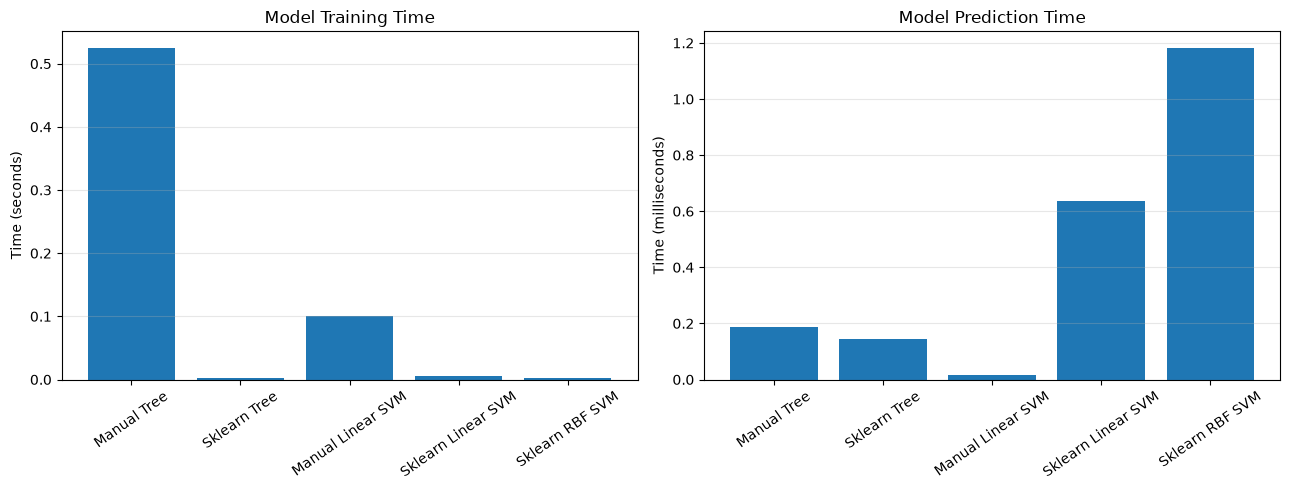

In [150]:

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Training time
axes[0].bar(
    final_results["Model"],
    final_results["Train Time (s)"]
)
axes[0].set_title("Model Training Time")
axes[0].set_ylabel("Time (seconds)")

# Prediction time
axes[1].bar(
    final_results["Model"],
    final_results["Predict Time (ms)"]
)
axes[1].set_title("Model Prediction Time")
axes[1].set_ylabel("Time (milliseconds)")

for ax in axes:
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


### Confusion Matrices for All Five Models

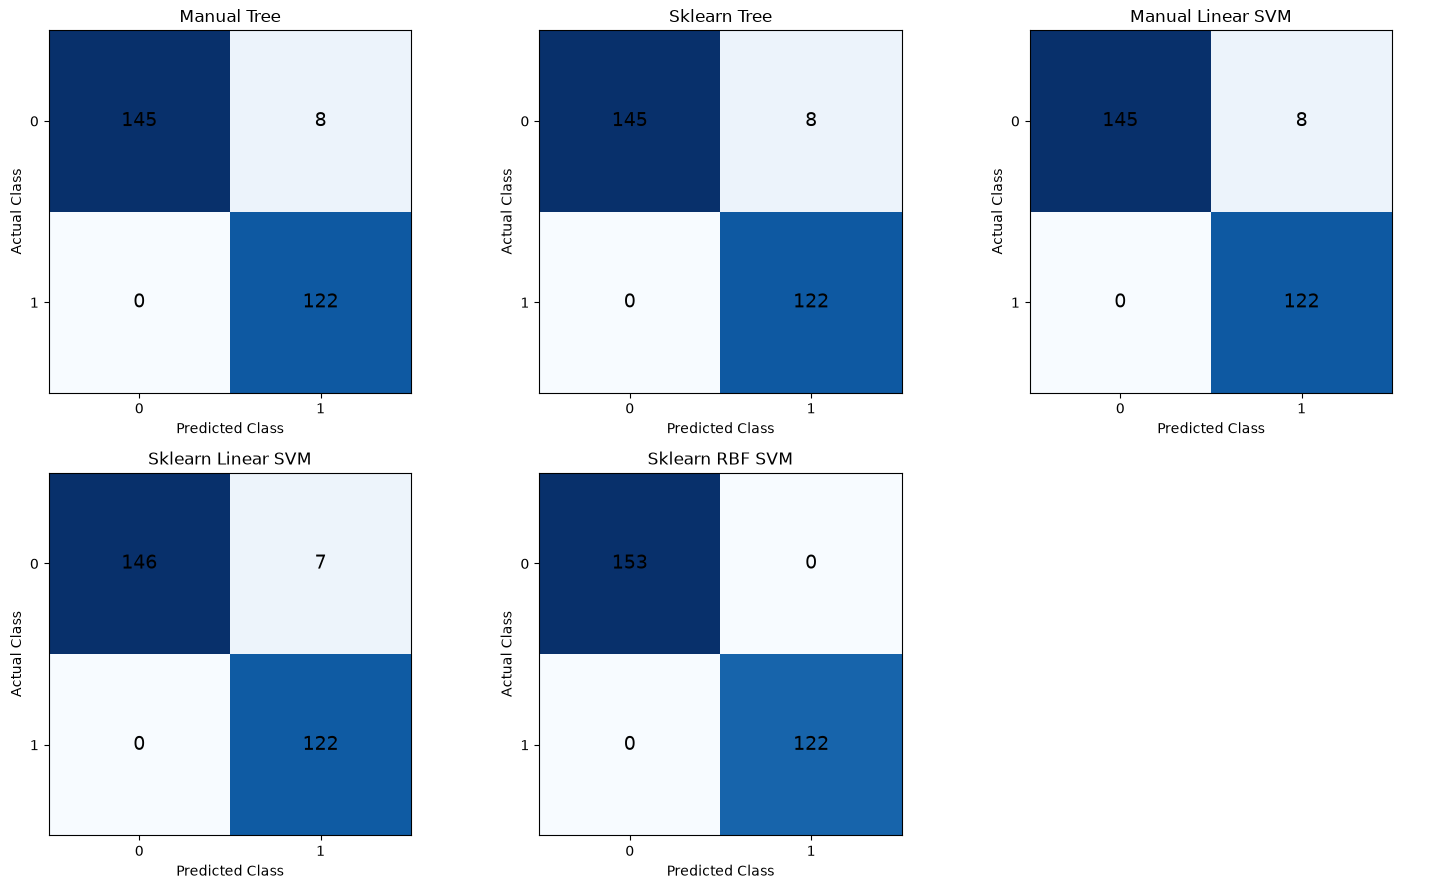

In [151]:

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, (name, predictions) in zip(
    axes.ravel(), final_predictions.items()
):

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    ax.imshow(cm, cmap="Blues")

    # Display counts inside cells
    for i in range(2):
        for j in range(2):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center",
                va="center",
                fontsize=14
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.set_title(name)

# Hide unused subplot
axes[1, 2].axis("off")

plt.tight_layout()
plt.show()


### Conclusion — Interpretability, Scaling, Overfitting, and Model Complexity

**1. Interpretability:** Decision Trees are the most interpretable because their predictions can be explained through feature-based splitting rules. Linear SVMs are moderately interpretable through their weights and bias, while RBF SVMs are less interpretable due to their nonlinear decision boundaries.

**2. Feature Scaling:** Decision Trees do not require feature scaling because they split data based on feature thresholds. Both Linear and RBF SVMs are sensitive to feature magnitudes and benefit from standardization.

**3. Overfitting:** Decision Trees can overfit when their depth increases, creating overly complex decision rules. Linear SVMs control overfitting through the regularization parameter C, while RBF SVMs depend on both C and gamma. The difference between training and testing accuracy helps identify possible overfitting.

**4. Model Complexity:** Decision Tree complexity depends on the number of nodes, leaves, and depth. Linear SVMs have relatively simple models defined by their weight vectors and bias. RBF SVMs are more computationally complex because predictions depend on support vectors and kernel evaluations.

**Overall:** Decision Trees offer better interpretability, Linear SVMs provide simpler decision boundaries, and RBF SVMs offer greater flexibility for nonlinear patterns. The appropriate model depends on predictive performance, computational efficiency, interpretability, and generalization.